# Comprendre `src/myqlm_d1q3.py`, pas à pas

Ce notebook exécute le programme **morceau par morceau** et vérifie chaque étape.
Exécute les cellules une par une avec `Shift+Entrée` et lis les sorties.

**Ce que fait le programme** : simuler une tache d'encre qui diffuse (LBM D1Q3) **sur un ordinateur quantique simulé**, puis vérifier que le résultat est identique au LBM classique.

Un pas de temps = **encoder** → **collision** → **streaming** → **lire**.

Notations : $f^n_{a,i}$ = quantité de fluide au nœud $i$, direction $a$ (repos, droite, gauche), temps $n$.

In [1]:
import sys; sys.path.insert(0, "..")          # pour trouver le dossier src/
import numpy as np
import matplotlib.pyplot as plt
from qat.lang.AQASM import Program, X
from qat.qpus import PyLinalg
from src import myqlm_d1q3 as q
np.set_printoptions(precision=3, suppress=True)
print("imports OK")

imports OK


## 1. Le point de départ : le tableau classique $f$

$f$ est un tableau de forme **(3, N)** : 3 lignes (directions $a$), N colonnes (nœuds $i$).
On part d'une gaussienne à l'équilibre : $f_{a,i} = w_a\,\rho_i$.

forme de f0 : (3, 16)   (3 directions x 16 nœuds)
poids w     : [0.667 0.167 0.167]   vitesses c : [ 0  1 -1]


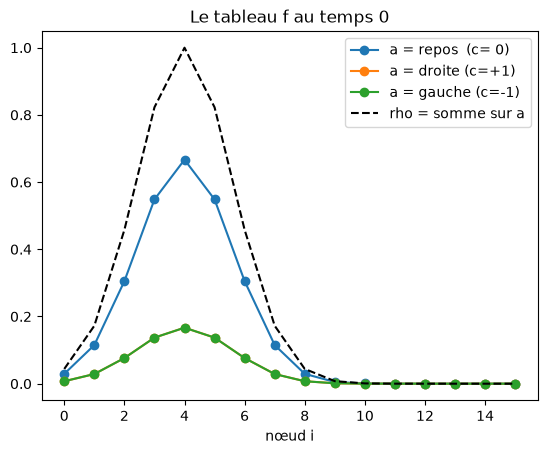

In [2]:
N, n = 16, 4                     # 16 nœuds = 2**4, donc 4 qubits de position
tau = 0.8
x = np.arange(N)
rho0 = np.exp(-(x - 4)**2 / (2 * 1.6**2))      # densité initiale : une bosse en x = 4
f0 = np.outer(q.W, np.ones(1)) * rho0          # f0[a, i] = w_a * rho_i

print("forme de f0 :", f0.shape, "  (3 directions x 16 nœuds)")
print("poids w     :", q.W, "  vitesses c :", q.C_VEL)
for a, nom in enumerate(["repos  (c= 0)", "droite (c=+1)", "gauche (c=-1)"]):
    plt.plot(x, f0[a], "o-", label=f"a = {nom}")
plt.plot(x, f0.sum(0), "k--", label="rho = somme sur a")
plt.xlabel("nœud i"); plt.legend(); plt.title("Le tableau f au temps 0"); plt.show()

## 2. La version classique d'un pas (notre référence)

**Collision** : chaque colonne est multipliée par la matrice $C = (1-1/\tau)I + M/\tau$ (3×3).
**Streaming** : la ligne « droite » est décalée d'une case vers la droite, la ligne « gauche » vers la gauche.

In [3]:
C = q.collision_matrix(tau)
print("C =\n", C)
print("somme de chaque colonne :", C.sum(0), " -> 1 partout = la masse est conservée")

f1 = q.classical_step(f0, tau)
print("masse avant :", f0.sum().round(6), " après :", f1.sum().round(6))

C =
 [[ 0.583  0.833  0.833]
 [ 0.208 -0.042  0.208]
 [ 0.208  0.208 -0.042]]
somme de chaque colonne : [1. 1. 1.]  -> 1 partout = la masse est conservée
masse avant : 4.002072  après : 4.002072


## 3. L'encodage : le tableau devient un vecteur d'état quantique

Les 3×16 nombres sont rangés dans les **amplitudes** de 6 qubits (2 de vitesse + 4 de position), soit $2^6 = 64$ amplitudes.
Ordre : d'abord les 16 valeurs « repos », puis « droite », puis « gauche », puis 16 zéros (état de vitesse |11⟩ inutilisé).
On divise par la norme, car un état quantique doit avoir une norme de 1.

taille du vecteur : (64,)   norme : 1.0


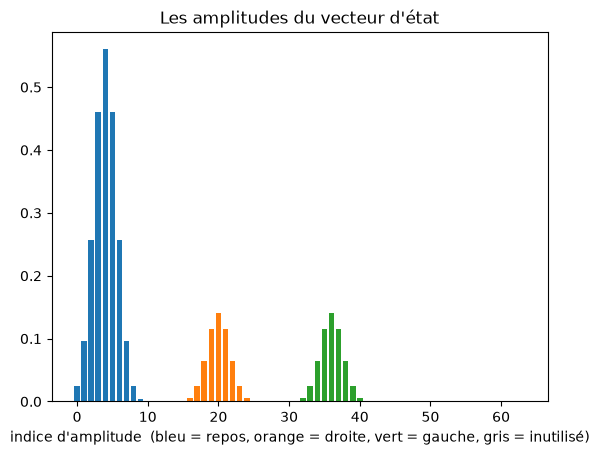

décodage = tableau de départ ? True


In [4]:
psi = q.encode(f0)
print("taille du vecteur :", psi.shape, "  norme :", np.linalg.norm(psi).round(6))

couleurs = ["tab:blue"]*16 + ["tab:orange"]*16 + ["tab:green"]*16 + ["lightgray"]*16
plt.bar(range(64), psi, color=couleurs)
plt.xlabel("indice d'amplitude  (bleu = repos, orange = droite, vert = gauche, gris = inutilisé)")
plt.title("Les amplitudes du vecteur d'état"); plt.show()

f_back = q.decode(psi, N, f0.sum())
print("décodage = tableau de départ ?", np.allclose(f_back, f0))

## 4. La collision : rendre $C$ « quantique »

$C$ n'est pas unitaire, donc elle ne peut pas être une porte quantique directement.
On construit une matrice **unitaire $U$ (8×8)** sur [ancilla, vitesse₀, vitesse₁] dont le coin supérieur gauche vaut $C/s$ (block-encoding par dilatation).
Après la porte, on garde seulement les cas où l'ancilla vaut 0 (post-sélection).

In [5]:
U, s = q.collision_unitary(tau)
print("s (norme de C) =", round(s, 3))
print("U est unitaire ?", np.allclose(U @ U.T, np.eye(8)))
print("\ncoin supérieur gauche de U, multiplié par s (doit redonner C, plus une ligne/colonne de 0) :\n", U[:4, :4] * s)

# effet sur un seul nœud
f_noeud = np.array([0.5, 0.4, 0.1, 0.0])               # repos, droite, gauche, inutilisé
etat = f_noeud / np.linalg.norm(f_noeud)
sortie = U @ np.concatenate([etat, np.zeros(4)])       # ancilla dans |0>
garde = sortie[:4]                                      # ancilla mesurée = 0
p = garde @ garde
print("\nprobabilité que l'ancilla donne 0 :", round(p, 3))
print("état gardé (normalisé)            :", garde / np.sqrt(p))
attendu = (np.pad(C, ((0,1),(0,1))) @ f_noeud)
print("C @ f (normalisé), pour comparer :", attendu / np.linalg.norm(attendu))

s (norme de C) = 1.345
U est unitaire ? True

coin supérieur gauche de U, multiplié par s (doit redonner C, plus une ligne/colonne de 0) :
 [[ 0.583  0.833  0.833  0.   ]
 [ 0.208 -0.042  0.208  0.   ]
 [ 0.208  0.208 -0.042  0.   ]
 [ 0.     0.     0.     0.   ]]

probabilité que l'ancilla donne 0 : 0.72
état gardé (normalisé)            : [0.958 0.146 0.248 0.   ]
C @ f (normalisé), pour comparer : [0.958 0.146 0.248 0.   ]


## 5. Le streaming : un compteur contrôlé par la vitesse

On teste sur un **seul état de base** : une particule au nœud 3 qui va à droite (vitesse |01⟩).
Après le streaming, elle doit être au nœud 4. Puis une particule qui va à gauche doit reculer.

Rappel : MyQLM est **big-endian**, le premier qubit d'un registre est le bit de poids fort.

In [6]:
def tester_streaming(code_vitesse, noeud):
    prog = Program()
    vel = prog.qalloc(2); pos = prog.qalloc(n)
    # préparer |vitesse>|noeud> en basculant les bons bits
    for k, bit in enumerate(format(code_vitesse, "02b")):
        if bit == "1": prog.apply(X, vel[k])
    for k, bit in enumerate(format(noeud, f"0{n}b")):
        if bit == "1": prog.apply(X, pos[k])
    inc = q.increment(n)
    prog.apply(X, vel[0]); prog.apply(inc.ctrl(2), vel[0], vel[1], pos); prog.apply(X, vel[0])
    prog.apply(X, vel[1]); prog.apply(inc.dag().ctrl(2), vel[0], vel[1], pos); prog.apply(X, vel[1])
    res = PyLinalg().submit(prog.to_circ().to_job())
    etat = [s.state.int for s in res][0]
    return etat % N                                     # position finale

print("droite (|01>) depuis le nœud 3  -> nœud", tester_streaming(0b01, 3))
print("gauche (|10>) depuis le nœud 3  -> nœud", tester_streaming(0b10, 3))
print("repos  (|00>) depuis le nœud 3  -> nœud", tester_streaming(0b00, 3))
print("droite depuis le nœud 15 (bord) -> nœud", tester_streaming(0b01, 15), " (bords périodiques)")

droite (|01>) depuis le nœud 3  -> nœud 4
gauche (|10>) depuis le nœud 3  -> nœud 2
repos  (|00>) depuis le nœud 3  -> nœud 3
droite depuis le nœud 15 (bord) -> nœud 0  (bords périodiques)


## 6. Le circuit complet d'un pas

`step_program` assemble tout : préparation de l'état, collision, streaming.
On liste les portes, puis on compte les qubits.

In [7]:
prog = q.step_program(psi, n, tau)
circ = prog.to_circ()
print("nombre de qubits :", circ.nbqbits, " (1 ancilla + 2 vitesse + 4 position)")
for nom, params, qubits in circ.iterate_simple():
    print(f"{nom:10s} sur les qubits {qubits}")

nombre de qubits : 7  (1 ancilla + 2 vitesse + 4 position)
PREP       sur les qubits [1, 2, 3, 4, 5, 6]
COLLISION  sur les qubits [0, 1, 2]
X          sur les qubits [1]
C-C-C-C-C-X sur les qubits [1, 2, 4, 5, 6, 3]
C-C-C-C-X  sur les qubits [1, 2, 5, 6, 4]
C-C-C-X    sur les qubits [1, 2, 6, 5]
C-C-X      sur les qubits [1, 2, 6]
X          sur les qubits [1]
X          sur les qubits [2]
C-C-X      sur les qubits [1, 2, 6]
C-C-C-X    sur les qubits [1, 2, 6, 5]
C-C-C-C-X  sur les qubits [1, 2, 5, 6, 4]
C-C-C-C-C-X sur les qubits [1, 2, 4, 5, 6, 3]
X          sur les qubits [2]


## 7. Un pas quantique, comparé au classique

In [8]:
psi1, p1 = q.quantum_step(psi, n, tau)
f1_quantique = q.decode(psi1, N, f0.sum())
print("probabilité de succès de la post-sélection :", round(p1, 3))
print("écart max quantique vs classique :", np.abs(f1_quantique - f1).max())

probabilité de succès de la post-sélection : 0.553
écart max quantique vs classique : 1.1102230246251565e-16


## 8. Plusieurs pas : la diffusion complète

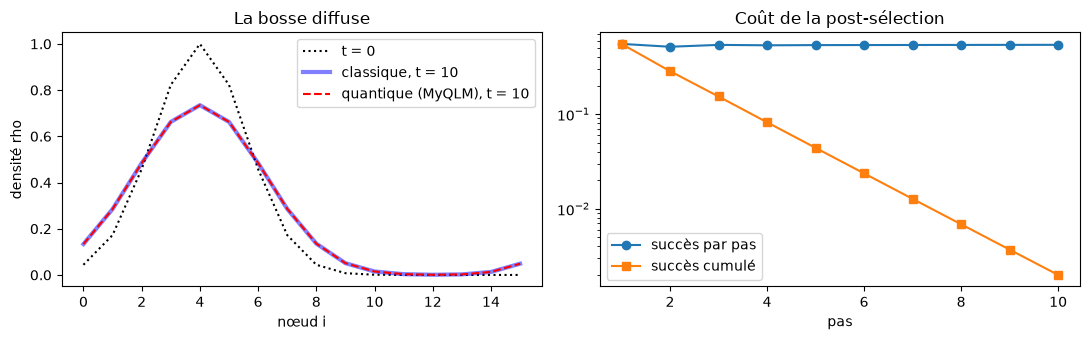

écart max après 10 pas : 4.996003610813204e-16


In [9]:
T = 10
hist, probs = q.run(f0, tau, T)
fc = f0.copy()
for _ in range(T):
    fc = q.classical_step(fc, tau)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x, f0.sum(0), "k:", label="t = 0")
ax[0].plot(x, fc.sum(0), "b-", lw=3, alpha=.5, label=f"classique, t = {T}")
ax[0].plot(x, hist[-1].sum(0), "r--", label=f"quantique (MyQLM), t = {T}")
ax[0].set_xlabel("nœud i"); ax[0].set_ylabel("densité rho"); ax[0].legend(); ax[0].set_title("La bosse diffuse")
ax[1].plot(range(1, T+1), probs, "o-", label="succès par pas")
ax[1].plot(range(1, T+1), np.cumprod(probs), "s-", label="succès cumulé")
ax[1].set_yscale("log"); ax[1].set_xlabel("pas"); ax[1].legend(); ax[1].set_title("Coût de la post-sélection")
plt.tight_layout(); plt.show()
print("écart max après", T, "pas :", np.abs(fc - hist[-1]).max())

## Ce qu'il faut retenir

1. **Encodage** : le tableau (3, N) est rangé dans les amplitudes de 2 + log₂N qubits.
2. **Collision** : la matrice $C$, non unitaire, est plongée dans une unitaire $U$ avec 1 ancilla ; on garde l'ancilla = 0.
3. **Streaming** : un incrémenteur sur le registre position, contrôlé par le registre vitesse.
4. **Résultat** : identique au LBM classique, mais chaque pas ne réussit qu'environ une fois sur deux, et ce coût se multiplie au fil des pas.

Pour aller plus loin : change `tau`, ou passe à l'ordre 1 avec `q.run(f0, tau, T, u=0.1)`.